In [1]:
from src.document_ingesition.document_processor import documentprocessor
from src.vector_store.vectorstore import Vectorstore
from pathlib import Path
from typing import List
from langchain_core.documents import Document
import re

processor = documentprocessor(
    chunk_size=700,
    chunk_overlap=50
)

# Load documents
urls_file = Path(r"data\url.txt")
urls = None
    
if urls_file.exists():
    with open(urls_file, 'r') as f:
        urls = [line.strip() for line in f if line.strip()]
chunks = processor.process_urls(urls)


# process_chunks: List[Document]=[]

# clean_docs:List[Document]=[]
# for doc in docs:
#     text = doc.page_content

#     # 1. Normalize excessive whitespace and consecutive blank lines
#     text = re.sub(r'\r\n|\r', '\n', text)
#     text = re.sub(r'\n{2,}', '\n\n', text)
#     text = re.sub(r'[ \t]+', ' ', text)
#     text = re.sub(r"\n+", "", text)
#     # 2. Strip common blog/web noise artifacts (header bars, nav lines)
#     text = re.sub(r'(?:\|\s*)+(?:Posts|Archive|Search|Tags|FAQ)\b.*', '', text, flags=re.IGNORECASE)

#     clean_docs.append(Document(page_content=text,metadata=doc.metadata.copy()))



    

print("Documents loaded:", len(chunks))

# Split documents into chunks

print("Chunks created:", len(chunks))

# Create the vector store
store = Vectorstore()
store.create_vectorstore(chunks)

print("Vector store created successfully!")


USER_AGENT environment variable not set, consider setting it to identify your requests.


32 documents cleaned ..ready to split

Documents loaded: 247
Chunks created: 247
Vector store created successfully!


c:\Users\KIIT\Desktop\DoRag_p\src\nodes\reactnodes.py:56: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily_tool = TavilySearchResults(max_results=3)


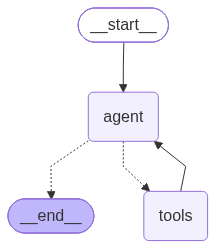

In [2]:
# Step 1: Bring your GraphBuilder into the notebook
# (Change 'my_workflow' to the real name of your Python file)
from src.grapg_builder.graph_builder import GraphBuilder
from src.config.config import Config

# Step 2: Set up your tools 
# (You need to plug in your real retriever and LLM here)
my_retriever =store.get_retriever() # Put your real retriever code here
my_llm = Config().get_llm()    
# res=my_llm.invoke("hiii")
# print(res,my_llm)# Put your real LLM code here

# Step 3: Create your graph builder
test_graph = GraphBuilder(retriever=my_retriever, llm=my_llm)
test=test_graph.build()
test
# Step 4: Make a name tag so the memory knows which notebook page to use
# my_config = {"configurable": {"thread_id": "test_chat_1"}}

# # Step 5: Ask a question and start the graph!
# my_question = "what is machine learning"
# final_answer = test_graph.run(question=my_question, config=my_config)

# # Step 6: Print the answer to see if it worked!
# print(f"this is final answer:\n\n{final_answer}")

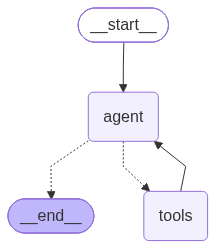

In [3]:
test=test_graph.build()
test

In [4]:
my_config = {"configurable": {"thread_id": "test_chat_1"}}

# Step 5: Ask a question and start the graph!
my_question = "Why is making videos with AI harder than making pictures?"
final_answer = test_graph.run(question=my_question, config=my_config)

# Step 6: Print the answer to see if it worked!
print(f"this is final answer:\n\n{final_answer}")

..............calling retriever tool............
this is final answer:

{'messages': [HumanMessage(content='Why is making videos with AI harder than making pictures?', additional_kwargs={}, response_metadata={}, id='f0b327f9-c8bc-4100-ad0e-db2505ab33df'), AIMessage(content=[{'arguments': '{"__arg1":"Why is making videos with AI harder than making pictures? Explain challenges in AI video generation compared with image generation: temporal consistency, motion, long sequences, compute/data, diffusion models."}', 'call_id': 'call_iLk7bD7SpmWU6G6qfMysUaQQ', 'name': 'retriever', 'type': 'function_call', 'id': 'fc_05faf97d006d6696006ace83f734bc87d19f9d53595859ebd1', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_05faf97d006d6696006ace83f6593887d19bfbd123c70163b1', 'created_at': 1791919094.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='r

In [5]:
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import HumanMessage,AIMessage,ToolMessage,SystemMessage
from pprint import pprint

res=getattr(final_answer['messages'][-1],'text')
res

'A picture only has to look convincing in one instant. A video has to make every instant convincing **and** make them fit together over time.\n\nThat adds several hard problems:\n\n- **Temporal consistency:** People, objects, lighting, and backgrounds should stay recognizable from frame to frame. Small inconsistencies can look like flicker or morphing.\n- **Plausible motion:** The model must work out how things move— including interactions, camera movement, and cause and effect—not just what they look like.\n- **More data and computation:** A video contains many frames, so generating it involves far more information than generating one image. High-quality video examples, especially videos paired with accurate text descriptions, are also harder to collect.\n- **Long-range coherence:** The model needs to keep track of what happened earlier so a scene remains consistent throughout the clip.\n\nIn short, video generation is like image generation plus the challenge of creating a coherent se